In [77]:
%pip install datasets

Note: you may need to restart the kernel to use updated packages.


In [78]:
from datasets import load_dataset

ds = load_dataset(
    "allenai/WildChat-1M",
    split="train",
    streaming=True
)

In [79]:
from itertools import islice

sample = list(islice(ds, 100_000))

KeyboardInterrupt: 

In [ ]:
print(ds.features)

{'conversation_hash': Value('string'), 'model': Value('string'), 'timestamp': Value('timestamp[us, tz=UTC]'), 'conversation': List({'content': Value('string'), 'country': Value('string'), 'hashed_ip': Value('string'), 'header': {'accept-language': Value('string'), 'user-agent': Value('string')}, 'language': Value('string'), 'redacted': Value('bool'), 'role': Value('string'), 'state': Value('string'), 'timestamp': Value('timestamp[us, tz=UTC]'), 'toxic': Value('bool'), 'turn_identifier': Value('int64')}), 'turn': Value('int64'), 'language': Value('string'), 'openai_moderation': List({'categories': {'harassment': Value('bool'), 'harassment/threatening': Value('bool'), 'harassment_threatening': Value('bool'), 'hate': Value('bool'), 'hate/threatening': Value('bool'), 'hate_threatening': Value('bool'), 'self-harm': Value('bool'), 'self-harm/instructions': Value('bool'), 'self-harm/intent': Value('bool'), 'self_harm': Value('bool'), 'self_harm_instructions': Value('bool'), 'self_harm_intent'

In [ ]:
import pandas as pd

rows = []

for conv in sample:
    messages = conv["conversation"]

    first_user = next(
        (m for m in messages if m["role"] == "user"),
        None
    )

    if first_user is not None:
        rows.append({
            "conversation_hash": conv["conversation_hash"],
            "language": conv["language"],
            "content": first_user["content"],
            "state": first_user["state"],
            "country": first_user["country"],
            "timestamp": first_user["timestamp"]
        })

df = pd.DataFrame(rows)

df.head()

,conversation_hash,language,content,state,country,timestamp
0,c9ec5b440fbdd2a269333dd241f32f64,English,Hey there! Are you familiar with reality shift...,Texas,United States,None
1,34f1581760df304d539e2fe4653b40d3,Spanish,Crea una imagen de una mujer corriente por la ...,A Coruña,Spain,None
2,cf1267ca6b2f6fccc9c36652a00059a1,English,"Old age PT hx of DM, HTN, dyslipidemia His ECG...",Mecca Region,Saudi Arabia,None
3,7f1c97a4f873cda8106b010d040be078,Catalan,calcula la mediana de followers: # Calcular la...,Barcelona,Spain,None
4,e98d3e74c57f9a65261df393d9124ac2,English,Hey there! Are you familiar with reality shift...,Texas,United States,None


In [ ]:
df["language"].value_counts().head(5)

English       14110
Chinese        8743
Russian        2609
French          681
Portuguese      547
Name: language, dtype: int64

In [ ]:
df["state"].value_counts().head(10)

Guangdong            1565
Moscow                899
Beijing               730
California            633
Auckland              601
Shanghai              531
Baden-Wurttemberg     465
Barcelona             426
Tokyo                 375
Wisconsin             364
Name: state, dtype: int64

In [ ]:
from collections import Counter
from zoneinfo import ZoneInfo

import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download


# 1. Keep one eligible first user prompt per conversation content hash

pacific_time = ZoneInfo("America/Los_Angeles")
periods = [
    ("Night", "00:00-05:59"),
    ("Morning", "06:00-11:59"),
    ("Afternoon", "12:00-17:59"),
    ("Evening", "18:00-23:59"),
]

period_counts = Counter()
first_10k_period_counts = Counter()
seen_hashes = set()
local_dates = []

english_conversations = 0
english_first_prompts = 0
california_conversations = 0
missing_user_timestamps = 0
last_turn_comparisons = 0
changed_time_bins = 0

for row_index, row in enumerate(sample):
    messages = row["conversation"]
    first_user_index = next(
        (i for i, message in enumerate(messages) if message["role"] == "user"),
        None,
    )

    english_conversations += row["language"] == "English"
    california_conversations += row["state"] == "California"

    if first_user_index is None:
        continue

    first_user = messages[first_user_index]
    english_first_prompts += first_user["language"] == "English"

    if (row["state"], row["country"]) != ("California", "United States"):
        continue
    if (first_user["state"], first_user["country"]) != ("California", "United States"):
        continue
    if first_user["language"] != "English":
        continue
    if not (first_user["content"] or "").strip():
        continue

    conversation_hash = row["conversation_hash"]
    if conversation_hash in seen_hashes:
        continue
    seen_hashes.add(conversation_hash)

    # 3. Use the first assistant response's completion time when needed

    timestamp = first_user["timestamp"]

    if timestamp is None:
        missing_user_timestamps += 1

        for message in messages[first_user_index + 1:]:
            if message["role"] == "user":
                break
            if message["role"] == "assistant":
                timestamp = message["timestamp"]
                break

    if timestamp is None:
        continue

    local_time = timestamp.astimezone(pacific_time)
    period_index = local_time.hour // 6

    period_counts[period_index] += 1
    if row_index < 10_000:
        first_10k_period_counts[period_index] += 1
    local_dates.append(local_time.date())

    # Check whether using the last-turn timestamp changes the time bin.
    last_turn_timestamp = row["timestamp"]
    if last_turn_timestamp is not None:
        last_turn_comparisons += 1
        last_turn_local = last_turn_timestamp.astimezone(pacific_time)
        changed_time_bins += last_turn_local.hour // 6 != period_index


# 2. Print aggregate results

total = sum(period_counts.values())

print(f"Training records read: {len(sample):,}")
print(f"English conversation-level labels: {english_conversations:,}")
print(f"English first-user-message labels: {english_first_prompts:,}")
print(f"California conversation-level state labels: {california_conversations:,}")
print(f"Eligible unique prompts before time assignment: {len(seen_hashes):,}")
print(f"Eligible prompts with missing user timestamps: {missing_user_timestamps:,}")
print(f"Eligible prompts assigned to a time period: {total:,}")

if local_dates:
    print(f"Pacific date range: {min(local_dates)} to {max(local_dates)}")

print(f"Time bins changed using the last-turn timestamp: "
      f"{changed_time_bins}/{last_turn_comparisons}")

print()
print(f"{'Period':<12} {'Pacific time':<14} {'Count':>5} {'Share':>8}")

for index, (name, hours) in enumerate(periods):
    count = period_counts[index]
    share = count / total if total else 0
    print(f"{name:<12} {hours:<14} {count:>5} {share:>8.1%}")

print(f"{'Total':<27} {total:>5} {1.0 if total else 0:>8.1%}")

Training records read: 100,000
English conversation-level labels: 49,794
English first-user-message labels: 48,789
California conversation-level state labels: 1,935
Eligible unique prompts before time assignment: 1,091
Eligible prompts with missing user timestamps: 1,091
Eligible prompts assigned to a time period: 1,091
Pacific date range: 2023-04-08 to 2023-05-16
Time bins changed using the last-turn timestamp: 51/1091

Period       Pacific time   Count    Share
Night        00:00-05:59      175    16.0%
Morning      06:00-11:59      313    28.7%
Afternoon    12:00-17:59      281    25.8%
Evening      18:00-23:59      322    29.5%
Total                        1091   100.0%


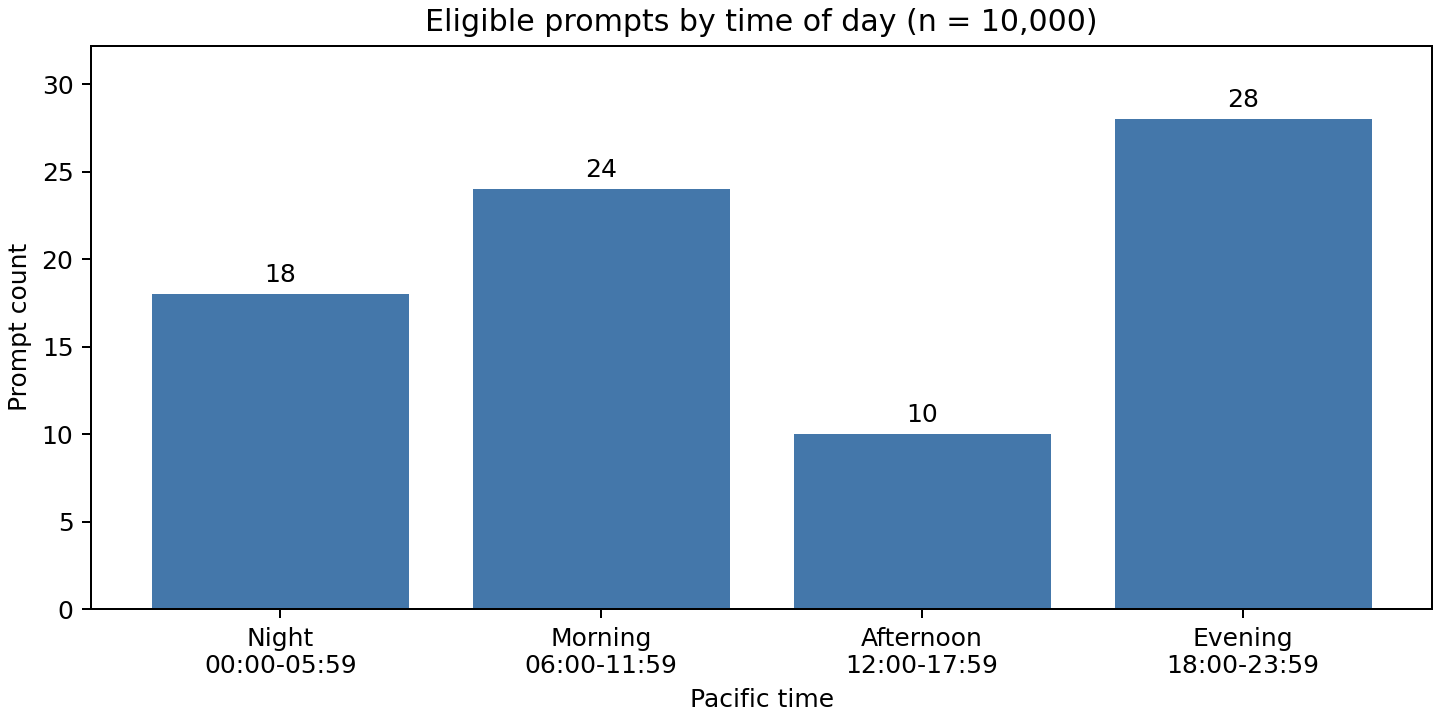

In [ ]:
import matplotlib.pyplot as plt

def plot_period_counts(counts_by_period, sample_size):
    counts = [counts_by_period[index] for index in range(len(periods))]
    labels = [f"{name}\n{hours}" for name, hours in periods]
    max_count = max(counts, default=0)

    fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
    bars = ax.bar(labels, counts, color="#4477AA")
    ax.bar_label(bars, padding=3)
    ax.set_title(f"Eligible prompts by time of day (n = {sample_size:,})")
    ax.set_xlabel("Pacific time")
    ax.set_ylabel("Prompt count")
    ax.set_ylim(0, max(1, max_count * 1.15))
    plt.show()

plot_period_counts(first_10k_period_counts, min(len(sample), 10_000))


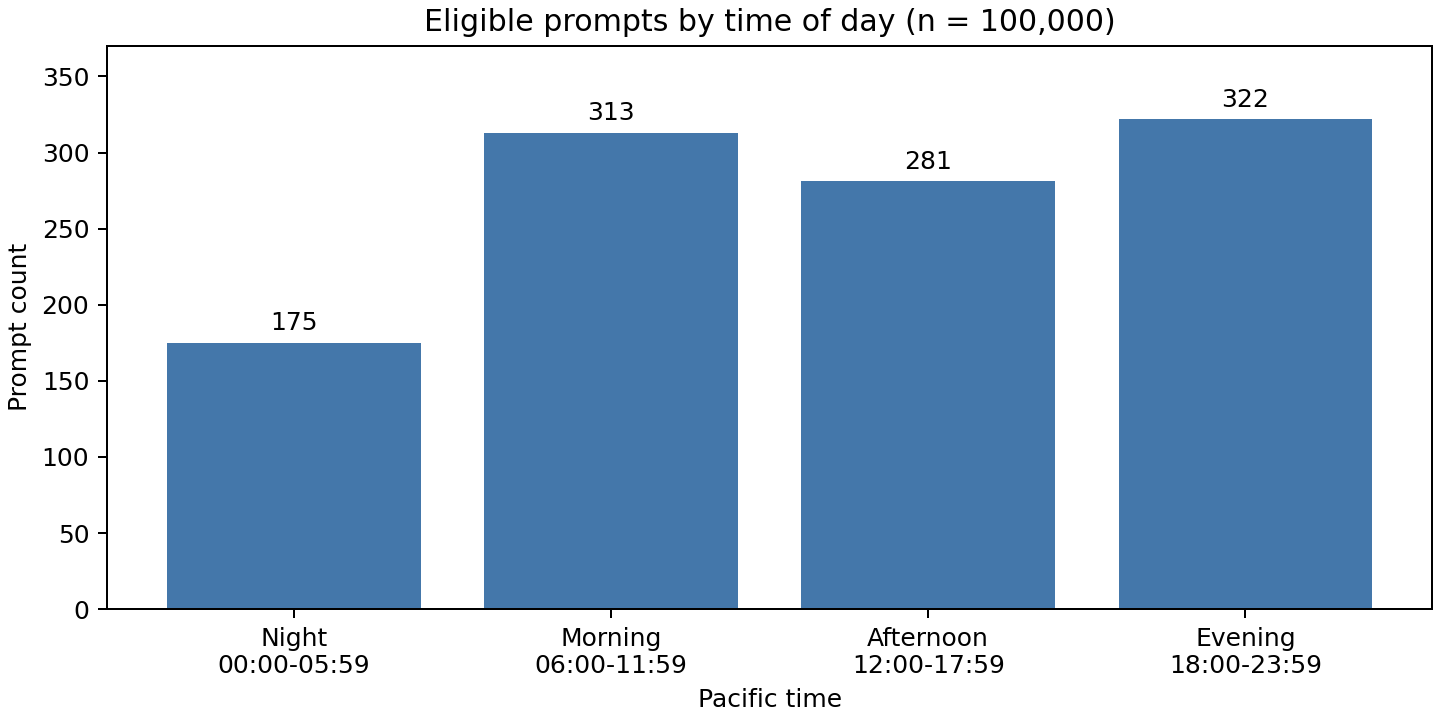

In [ ]:
plot_period_counts(period_counts, len(sample))
